# Learning Rate Scheduling


## Topics Covered

- Constant Learning Rate
- Time-Based Decay
- Step Decay
- Exponential Decay
- Piecewise Constant Decay
- Polynomial Decay
- Cosine Decay
- Cosine Decay with Restarts
- ReduceLROnPlateau
- Warmup Scheduling
- Cyclical Learning Rate (CLR)
- One Cycle Policy
- Custom Learning Rate Schedulers
- Learning Rate Finder
- Scheduler Comparison
- Full MNIST Training Example


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


## Helper Function for Plotting

In [ ]:

def plot_schedule(scheduler, steps=2000, title="Learning Rate Schedule"):
    lrs = [scheduler(step).numpy() for step in range(steps)]

    plt.figure(figsize=(12,5))
    plt.plot(lrs)
    plt.title(title)
    plt.xlabel("Steps")
    plt.ylabel("Learning Rate")
    plt.grid(True)
    plt.show()


## Exponential Decay

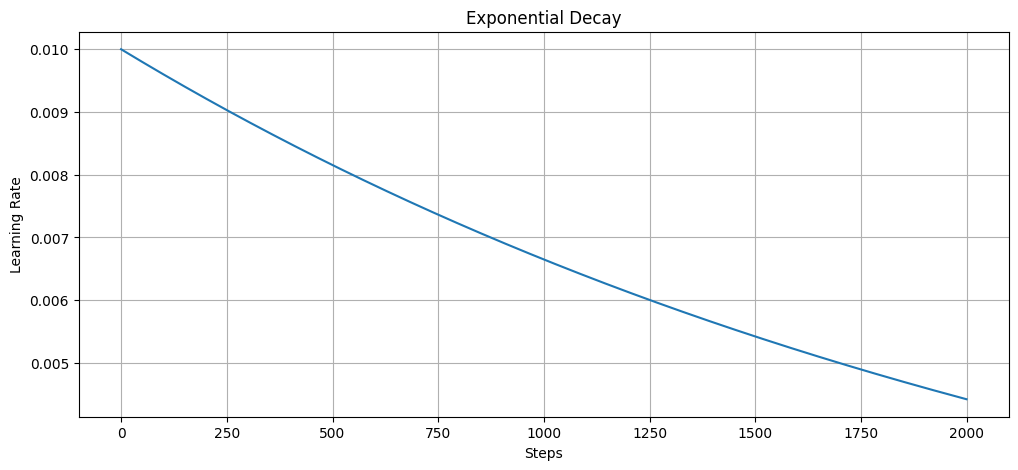

In [ ]:

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.01,
    decay_steps=100,
    decay_rate=0.96
)

plot_schedule(lr_schedule, title="Exponential Decay")


## Piecewise Constant Decay

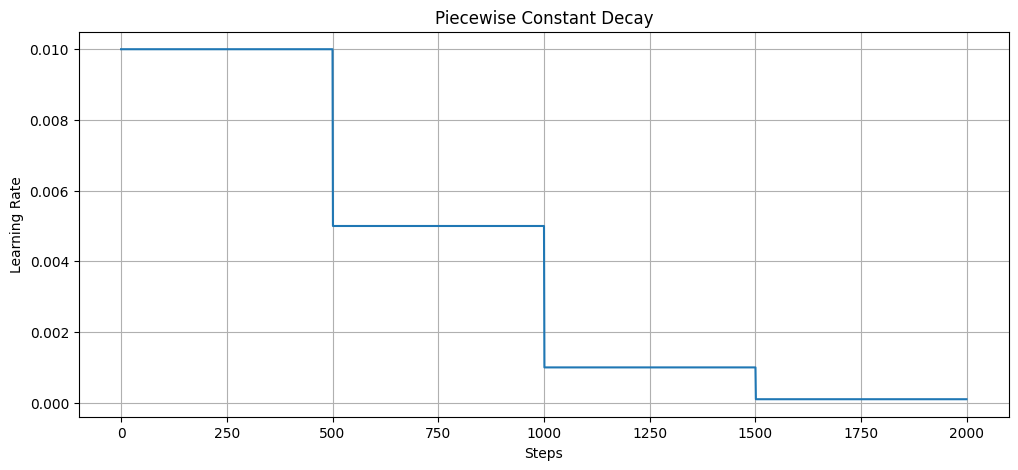

In [ ]:

lr_schedule = tf.keras.optimizers.schedules.PiecewiseConstantDecay(
    boundaries=[500, 1000, 1500],
    values=[0.01, 0.005, 0.001, 0.0001]
)

plot_schedule(lr_schedule, title="Piecewise Constant Decay")


## Polynomial Decay

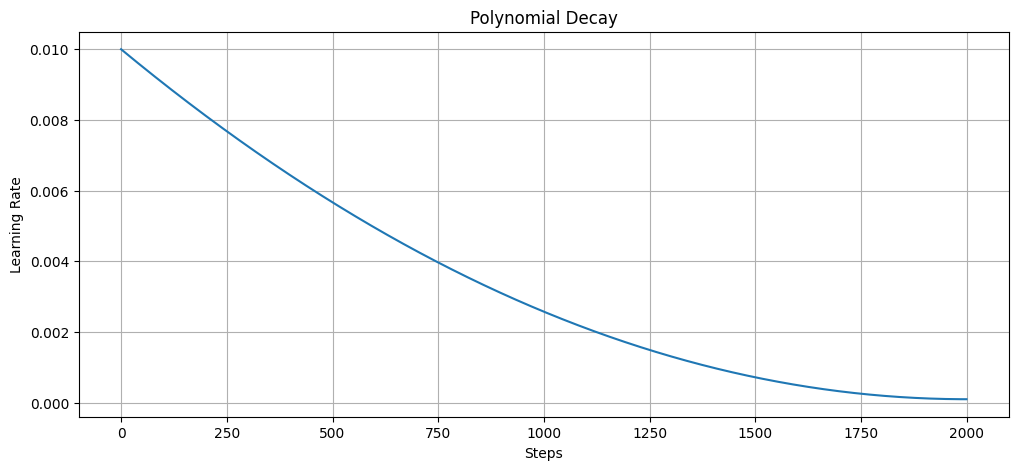

In [ ]:

lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=0.01,
    decay_steps=2000,
    end_learning_rate=0.0001,
    power=2
)

plot_schedule(lr_schedule, title="Polynomial Decay")


## Cosine Decay

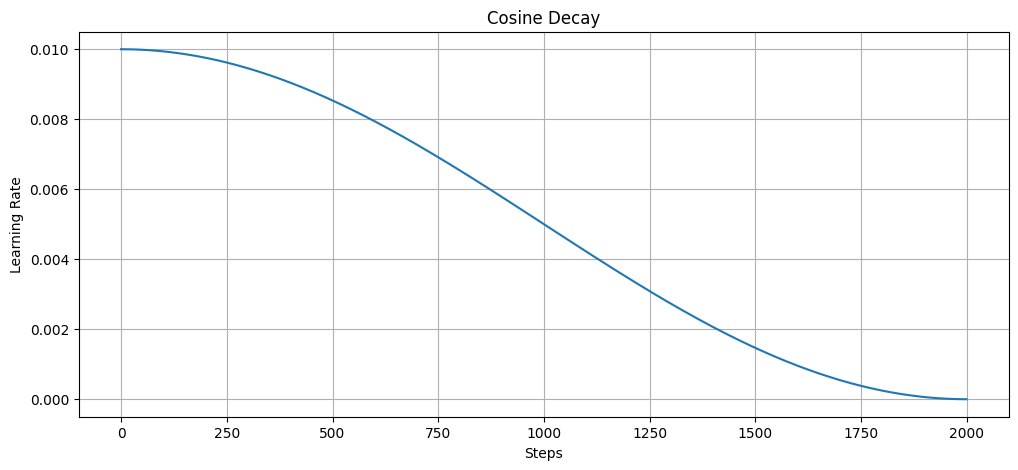

In [ ]:

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.01,
    decay_steps=2000
)

plot_schedule(lr_schedule, title="Cosine Decay")


## Cosine Decay with Restarts

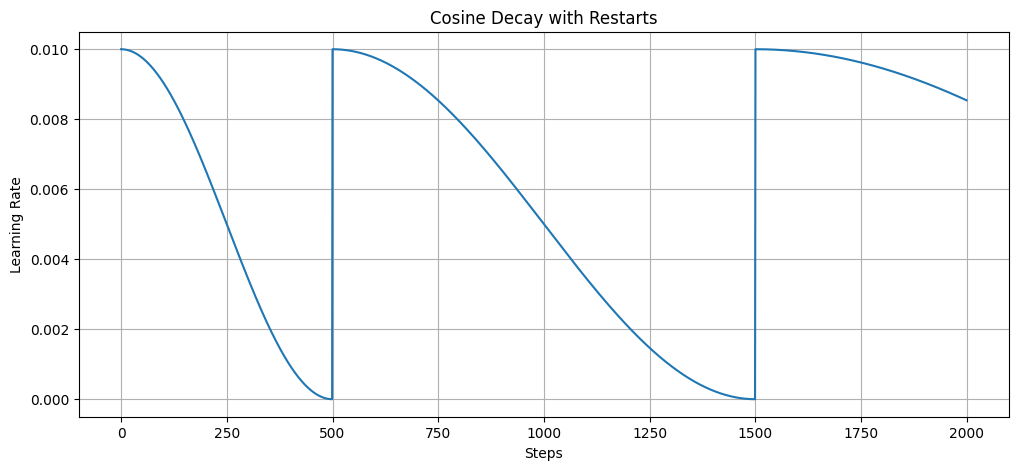

In [ ]:

lr_schedule = tf.keras.optimizers.schedules.CosineDecayRestarts(
    initial_learning_rate=0.01,
    first_decay_steps=500
)

plot_schedule(lr_schedule, title="Cosine Decay with Restarts")


## Warmup Scheduler

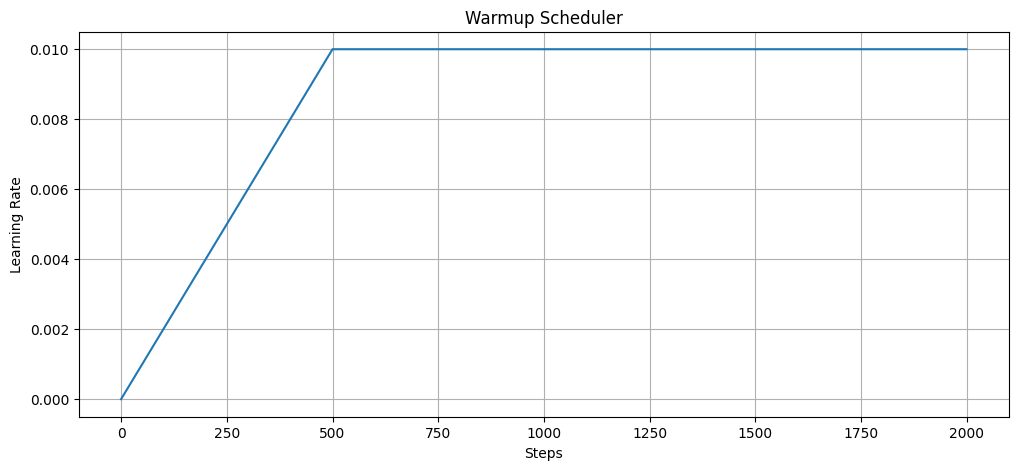

In [ ]:

def warmup_schedule(step):
    warmup_steps = 500
    base_lr = 0.01

    if step < warmup_steps:
        return tf.cast(base_lr * (step / warmup_steps), tf.float32)
    else:
        return tf.cast(base_lr, tf.float32)

class WarmupSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __call__(self, step):
        return warmup_schedule(step)

lr_schedule = WarmupSchedule()

plot_schedule(lr_schedule, title="Warmup Scheduler")


## Cyclical Learning Rate

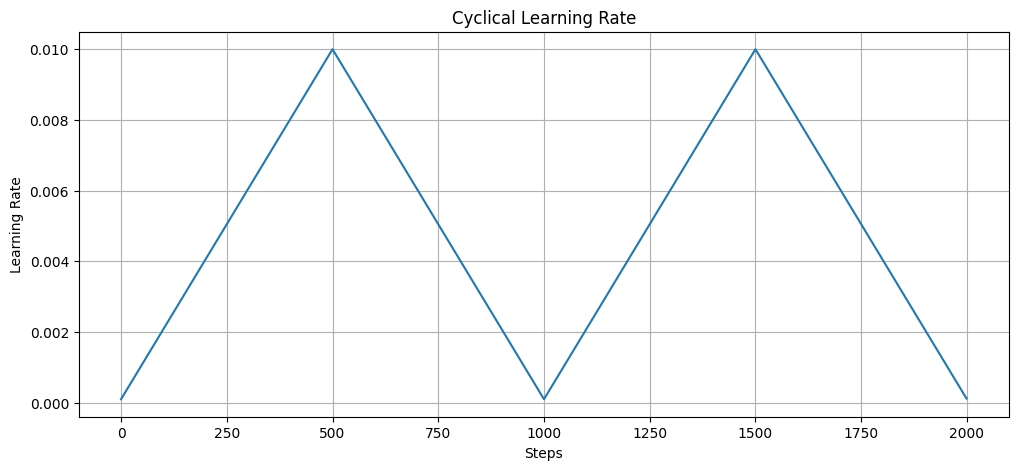

In [ ]:

class CyclicLR(tf.keras.optimizers.schedules.LearningRateSchedule):

    def __init__(self, initial_lr, maximal_lr, step_size):
        self.initial_lr = initial_lr
        self.maximal_lr = maximal_lr
        self.step_size = step_size

    def __call__(self, step):
        cycle = tf.floor(1 + step / (2 * self.step_size))
        x = tf.abs(step / self.step_size - 2 * cycle + 1)

        lr = self.initial_lr + (
            self.maximal_lr - self.initial_lr
        ) * tf.maximum(0.0, (1 - x))

        return lr

lr_schedule = CyclicLR(
    initial_lr=1e-4,
    maximal_lr=1e-2,
    step_size=500
)

plot_schedule(lr_schedule, title="Cyclical Learning Rate")


## One Cycle Policy

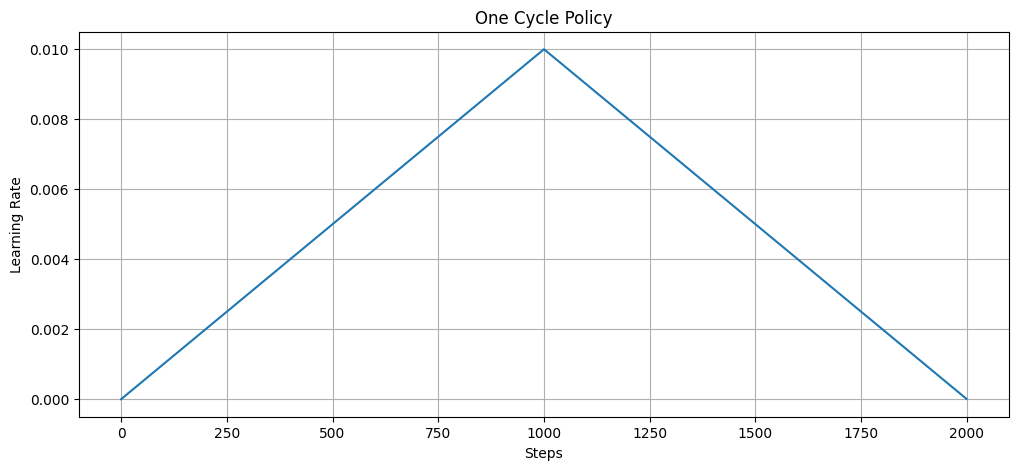

In [ ]:

class OneCycleLR(tf.keras.optimizers.schedules.LearningRateSchedule):

    def __init__(self, max_lr, total_steps):
        self.max_lr = max_lr
        self.total_steps = total_steps

    def __call__(self, step):

        half = self.total_steps // 2

        if step < half:
            return tf.cast(self.max_lr * (step / half), tf.float32)
        else:
            return tf.cast(
                self.max_lr * (1 - ((step - half) / half)),
                tf.float32
            )

lr_schedule = OneCycleLR(
    max_lr=0.01,
    total_steps=2000
)

plot_schedule(lr_schedule, title="One Cycle Policy")


## ReduceLROnPlateau

In [ ]:

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.1,
    patience=5,
    verbose=1,
    min_lr=1e-6
)

print(reduce_lr)


## Full MNIST Training Example

In [ ]:

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.001,
    decay_steps=1000
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=lr_schedule
)

model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=64
)


Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9280 - loss: 0.2493 - val_accuracy: 0.9613 - val_loss: 0.1308
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9691 - loss: 0.1095 - val_accuracy: 0.9637 - val_loss: 0.1244
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9697 - loss: 0.1075 - val_accuracy: 0.9637 - val_loss: 0.1244
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9697 - loss: 0.1075 - val_accuracy: 0.9637 - val_loss: 0.1244
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9697 - loss: 0.1075 - val_accuracy: 0.9637 - val_loss: 0.1244



# Final Recommendations

| Scenario | Best Scheduler |
|---|---|
| Beginner Projects | ReduceLROnPlateau |
| CNNs | CosineDecay |
| Transformers | Warmup + Cosine |
| Small Datasets | Step Decay |
| Research | OneCycle |
| Fast Training | Cyclical LR |
